# Mori-Zwanzig Regression on the Van der Pol oscillator
## AI INFN Hackathon@Ferrara · 2 December 2026
**Alessandro Gabbana** ([alessandro.gabbana@unife.it](mailto:alessandro.gabbana@unife.it)) · **André Freitas** ([Andre.Freitas@roma2.infn.it](mailto:Andre.Freitas@roma2.infn.it))

---

The **Mori-Zwanzig (MZ) formalism** provides a rigorous framework for deriving
effective equations for a subset of *resolved* variables when part of the system is hidden.

We study the **Van der Pol oscillator** (2D):

$$\dot{x} = \mu\!\left(x - \frac{x^3}{3} - y\right), \qquad \dot{y} = \frac{x}{\mu}$$

but suppose we observe **only** $x(t)$ while $y(t)$ is **unresolved**.

The reduced 1D dynamics are **non-Markovian**: the future of $x$ depends on its entire past,
because $y$ encodes information about $x$'s history.  The MZ formalism expresses this as

$$\boxed{x_{n+1} \approx \sum_{k=0}^{K-1} \Omega_k(x_{n-k})}$$

where $\Omega_0$ is the **Markovian** (instantaneous) operator and $\Omega_{k\ge 1}$ are
**memory kernels** that capture contributions from $k$ steps in the past.

In this notebook we learn the $\Omega_k$ from trajectory data.

In [11]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


## 1. The Van der Pol Oscillator


We solve the full 2D system with `scipy.integrate.solve_ivp` and visualise a trajectory.

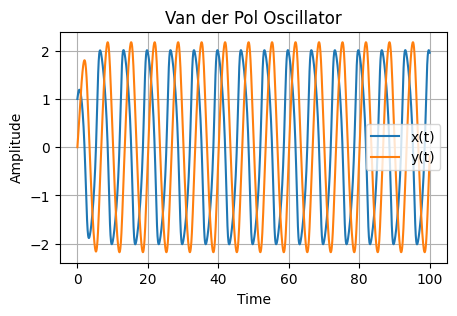

In [12]:
from scipy.integrate import solve_ivp

# Van der Pol oscillator ODE system
def vanderpol(t, z, mu):
    x, y = z
    dydt = x / mu
    dxdt = mu * (x - x**3 / 3 - y)
    return [dxdt, dydt]

# Parameters
mu = 1.0

z0 = [1.0, 0.0]
t_span = (0, 100)
t_eval = np.linspace(t_span[0], t_span[1], 2001)

solution = solve_ivp(vanderpol, t_span, z0, args=(mu,), t_eval=t_eval)

t = solution.t
x = solution.y[0]
y = solution.y[1]

plt.figure(figsize=(5, 3))
plt.plot(t, x, label="x(t)")
plt.plot(t, y, label="y(t)")
plt.title('Van der Pol Oscillator')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

## 2. Data Generation

We generate trajectories by perturbing the initial conditions.
From each trajectory we keep **only** the resolved variable $x(t)$, discarding $y(t)$.

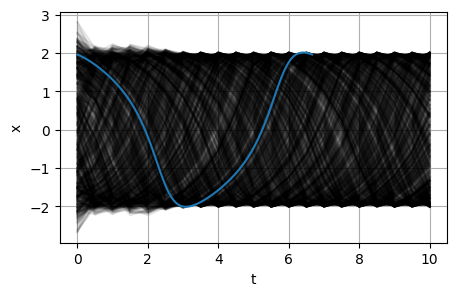

In [13]:
# generate initial samples by integrating for one period
period  = 6.663
tSpanIC = np.linspace(0, period, 101)
ICSol   = solve_ivp(vanderpol, tSpanIC[[0, -1]], solution.y[:, -1], args=(mu,), t_eval=tSpanIC)
initialSamples = ICSol.y.T[:-1, :]

tEnd = 10       # length of signal of the data
sampleN = 20    # number of timesteps
perturbN = 10   # number of random perturbations of initial conditions

tSpanSamplePaths = np.linspace(0, tEnd, sampleN + 1)

data = np.zeros([perturbN * len(initialSamples), 2, len(tSpanSamplePaths)])

plt.figure(figsize=(5, 3))

for i in range(len(initialSamples)):
    for j in range(perturbN):
        IC = initialSamples[i, :] + np.sqrt(0.1) * np.random.randn(2)
        sampleTraj = solve_ivp(vanderpol, tSpanSamplePaths[[0, -1]], IC, args=(mu,), t_eval=tSpanSamplePaths)
        plt.plot(tSpanSamplePaths, sampleTraj.y[0, :], color='k', alpha=0.1)
        data[i * perturbN + j, 0, :] = sampleTraj.y[0, :]
        data[i * perturbN + j, 1, :] = sampleTraj.y[1, :]

plt.plot(tSpanIC, ICSol.y[0, :])
plt.xlabel('t')
plt.ylabel('x')
plt.grid(True)
plt.show()

In [14]:
# focus only on the first dimension, reducing the system
data_full = data.copy()
data = data_full[:, 0, :].copy()

print('Data shape: ')
print(data.shape)
print('(ntraj, nsteps)')
ntraj, nsteps = data.shape
dim = 1

Data shape: 
(1000, 21)
(ntraj, nsteps)


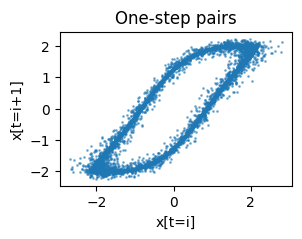

In [15]:
plt.figure(figsize=(3, 2))
for i in range(nsteps - 1):
    plt.scatter(data[:, i], data[:, i + 1], color='C0', s=1, alpha=0.5)
plt.title('One-step pairs')
plt.xlabel('x[t=i]')
plt.ylabel('x[t=i+1]')
plt.show()

## 3. The Mori–Zwanzig Framework

For the full 2D state $(x, y)$, knowing the current state uniquely determines the future.
Once we **project** onto $x$ alone, the missing $y$ information makes the dynamics appear
history-dependent.

In **discrete time**, truncating the memory at depth $K$ and neglecting the orthogonal
fluctuation, the MZ ansatz becomes:

$$x_{n+1} \approx \Omega_0(x_n) + \Omega_1(x_{n-1}) + \cdots + \Omega_{K-1}(x_{n-K+1})$$

### Sequential regression algorithm

Given trajectories $\{x_n^{(i)}\}$, we fit the operators greedily one at a time.
The input is always $x_0$ (the trajectory's starting value):

| Step $h$ | Target $Y$ | Operator learned |
|----------|-----------|------------------|
| $0$ | $x_1$ | $\Omega_0$: Markovian prediction |
| $1$ | $x_2 - \Omega_0(x_1)$ | $\Omega_1$: first memory correction |
| $2$ | $x_3 - \Omega_0(x_2) - \Omega_1(x_1)$ | $\Omega_2$: second memory correction |
| $h$ | $x_{h+1} - \sum_{k<h}\Omega_k(x_{h-k})$ | $\Omega_h$ |

At **prediction** time we shift the role of $x_0$ to any $x_{n-k}$:

$$\hat{x}_{n+1} = \sum_{k=0}^{K-1} \Omega_k(x_{n-k})$$

## 4. Training Polynomial MZ Operators

We fit each $\Omega_h$ as a degree-$d$ polynomial using least-squares (`np.polyfit`).

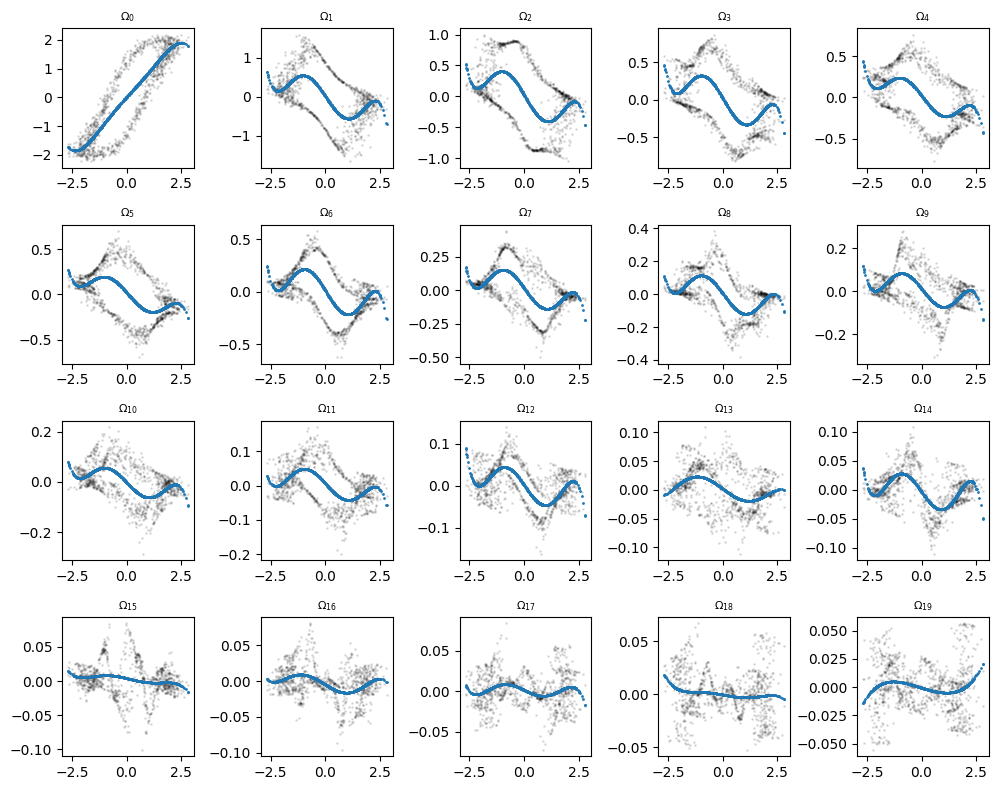

In [16]:
polynomials = []
polyDeg = 5

historyN = nsteps - 1  # number of memory operators = number of timesteps of history

ncol = 5
rowN = int(np.ceil(historyN / ncol))

fig, ax = plt.subplots(rowN, ncol, figsize=(ncol * 2, rowN * 2))
ax = np.reshape(ax, (rowN * ncol,))

X0 = data[:, 0].copy()
Y  = data[:, 1].copy()

for h in range(historyN):
    p = np.polyfit(X0, Y, deg=polyDeg)  # fit polynomial
    polynomials.append(p)

    pred = np.polyval(p, X0)

    ax[h].scatter(X0, Y,    s=1, color='k',         alpha=0.1)
    ax[h].scatter(X0, pred, s=1, color='C0')
    ax[h].set_title(f'$\\Omega_{{{h}}}$', fontsize=8)

    if h < historyN - 1:
        Y = data[:, 2 + h].copy()
        for k in range(h + 1):
            Y -= np.polyval(polynomials[k], data[:, 1 + h - k])

fig.tight_layout()
plt.show()

## 5. Evaluation

We generate a **held-out test trajectory** (never seen during training).
The first $K$ values serve as the initial history; the model then predicts the rest.

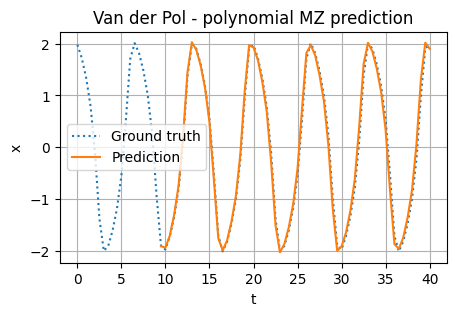

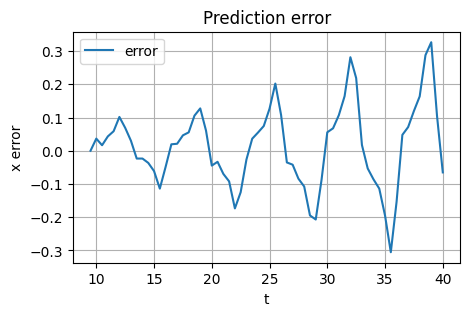

In [17]:
# generate ground truth test trajectory
IC = initialSamples[0] + np.sqrt(0.1) * np.random.randn(2)

test_multiplier = 4
tSpanTest = np.linspace(0, tEnd * test_multiplier, sampleN * test_multiplier + 1)

testTraj = solve_ivp(vanderpol, tSpanTest[[0, -1]], IC, args=(mu,), t_eval=tSpanTest)
testTraj = testTraj.y[0, :].copy()


def predict(steps, history, model):

    def oneStep(history, model):
        output = 0
        for i in range(historyN):
            output += model(history[-1 - i], i)
        return output

    solution = [history[-1]]
    for t in range(steps):
        sol = oneStep(history, model)
        history = np.roll(history, -1, axis=0)
        history[-1] = sol
        solution.append(sol)

    return np.array(solution)


def my_model(history_state, step):
    return np.polyval(polynomials[step], history_state)


prediction = predict(len(tSpanTest) - historyN, testTraj[:historyN], my_model)

plt.figure(figsize=(5, 3))
plt.plot(tSpanTest, testTraj, linestyle=':', label="Ground truth")
plt.plot(tSpanTest[historyN - 1:], prediction, label="Prediction")
plt.title('Van der Pol - polynomial MZ prediction')
plt.xlabel('t')
plt.ylabel('x')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(5, 3))
plt.plot(tSpanTest[historyN - 1:], prediction - testTraj[historyN - 1:], label="error")
plt.title('Prediction error')
plt.xlabel('t')
plt.ylabel('x error')
plt.legend()
plt.grid(True)
plt.show()

abs_error_poly = np.abs(prediction - testTraj[historyN - 1:])

## 6. Memory Kernel Decay

Memory operators should **decay** as $k$ increases:
the distant past carries progressively less information about the future.

We measure this with the relative $\ell^2$ norm of each operator evaluated on the training data:

$$\frac{\|\Omega_k\|}{\|\Omega_0\|}, \qquad
\|\Omega_k\| = \left(\sum_i \Omega_k(x_0^{(i)})^2\right)^{1/2}$$

If the memory kernel decays fast, a **short-memory** approximation is accurate.
A slow decay indicates that the unresolved variable $y$ has long-range influence on $x$.

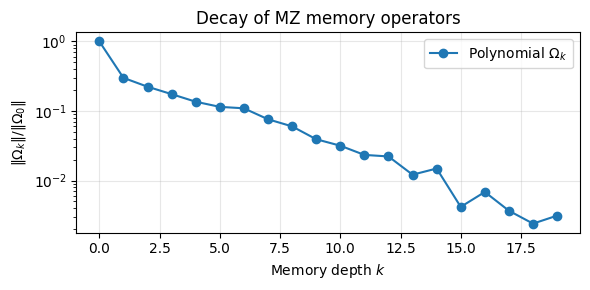

In [18]:
x_sample = data[:, 0]

norms_poly = np.zeros(historyN)

for k in range(historyN):
    value = np.polyval(polynomials[k], x_sample)
    norms_poly[k] = np.linalg.norm(value)

norms_poly = norms_poly / norms_poly[0]

plt.figure(figsize=(6, 3))
plt.semilogy(norms_poly, 'o-', color='C0', lw=1.5, label='Polynomial $\\Omega_k$')
plt.xlabel('Memory depth $k$')
plt.ylabel(r'$\|\Omega_k\| / \|\Omega_0\|$')
plt.title('Decay of MZ memory operators')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Exercises

1. How many memory terms do we actually need?  We sweep $K = 1, 2, \ldots, K_{\max}$
and measure the test-set MSE as a function of depth. $K = 1$ is the **Markov approximation** (no memory). <br> Try to see if and how the result is effected by the polynamial degree.

2. Replace polynomial regression with small MLP, repeat the analysis